In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [3]:
# Load training and testing datasets
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

# Separate images and labels
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

# Display dataset shapes
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (27455, 784)
Testing Data: (7172, 784)


In [4]:
# Map labels into consecutive values from 0 to 23
classes = np.unique(y_train)
label_map = {label: i for i, label in enumerate(classes)}

y_train = np.array([label_map[label] for label in y_train])
y_test = np.array([label_map[label] for label in y_test])

# Normalize pixel values between 0 and 1
X_train = X_train / 255.0
X_test = X_test / 255.0

# Flatten images into 784 values
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (27455, 784)
Testing Shape: (7172, 784)


In [5]:
# Create Feedforward Neural Network
model = tf.keras.Sequential([
    # Input layer
    tf.keras.layers.Input(shape=(784,)),

    # Hidden layers
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),

    # Output layer for 24 ASL alphabet classes
    tf.keras.layers.Dense(24, activation='softmax')
])

# Display model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,296 (430.84 KB)

 Trainable params: 110,296 (430.84 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
687/687 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3391 - loss: 2.1626 - val_accuracy: 0.5247 - val_loss: 1.5047
Epoch 2/10
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5921 - loss: 1.2915 - val_accuracy: 0.6267 - val_loss: 1.1659
Epoch 3/10
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6974 - loss: 0.9428 - val_accuracy: 0.7385 - val_loss: 0.8043
Epoch 4/10
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7765 - loss: 0.7075 - val_accuracy: 0.8266 - val_loss: 0.5744
Epoch 5/10
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8334 - loss: 0.5371 - val_accuracy: 0.8800 - val_loss: 0.4069
Epoch 6/10
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8728 - loss: 0.4087 - val_accuracy: 0.8947 - val_loss: 0.3518
Epoch 7/10
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9120 - loss: 0.3057 - val_accuracy: 0.9372 - val_loss: 0.2186
Epoch 8/10
687/687 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9302 - loss: 0.2320 - val_accuracy: 0.

In [8]:
train_loss, train_acc = model.evaluate(X_train, y_train)
test_loss, test_acc = model.evaluate(X_test, y_test)

print("Training Accuracy:", train_acc * 100, "%")
print("Testing Accuracy:", test_acc * 100, "%")
print("Training Loss:", train_loss)
print("Testing Loss:", test_loss)

858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9792 - loss: 0.0986
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7294 - loss: 1.1172
Training Accuracy: 97.92023301124573 %
Testing Accuracy: 72.93642163276672 %
Training Loss: 0.0986148864030838
Testing Loss: 1.1172208786010742


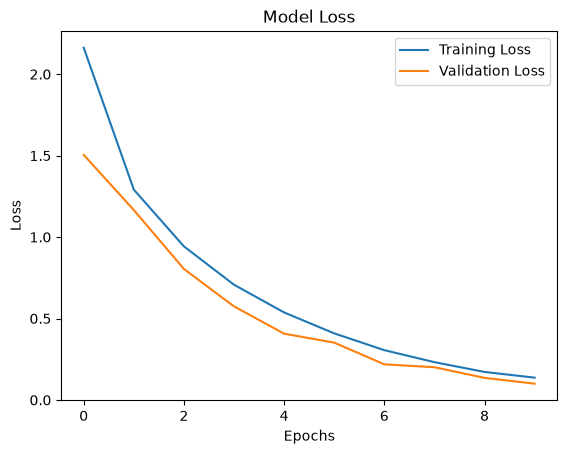

In [9]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
# Construct a Feedforward Neural Network to recognize different ASL
# alphabet hand gestures. Train the model and display training accuracy,
# testing accuracy and loss graph. Use – Dataset - Sign Language MNIST